In [144]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

In [145]:
data= "C:/Users/Admin/Desktop/datacamp/recipe_site_traffic_2212.csv"

In [146]:
recipe= pd.read_csv(data)

## Data Cleaning

In [147]:
recipe.head()

,recipe,calories,carbohydrate,sugar,protein,category,servings,high_traffic
0,1,NaN,NaN,NaN,NaN,Pork,6,High
1,2,35.48,38.56,0.66,0.92,Potato,4,High
2,3,914.28,42.68,3.09,2.88,Breakfast,1,NaN
3,4,97.03,30.56,38.63,0.02,Beverages,4,High
4,5,27.05,1.85,0.80,0.53,Beverages,4,NaN


In [148]:
recipe.shape

(947, 8)

In [149]:
recipe.columns

Index(['recipe', 'calories', 'carbohydrate', 'sugar', 'protein', 'category',
       'servings', 'high_traffic'],
      dtype='str')

In [150]:
recipe.info()

<class 'pandas.DataFrame'>
RangeIndex: 947 entries, 0 to 946
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   recipe        947 non-null    int64  
 1   calories      895 non-null    float64
 2   carbohydrate  895 non-null    float64
 3   sugar         895 non-null    float64
 4   protein       895 non-null    float64
 5   category      947 non-null    str    
 6   servings      947 non-null    str    
 7   high_traffic  574 non-null    str    
dtypes: float64(4), int64(1), str(3)
memory usage: 59.3 KB


In [151]:
recipe.duplicated().sum()

np.int64(0)

In [152]:
recipe.isna().sum()

recipe            0
calories         52
carbohydrate     52
sugar            52
protein          52
category          0
servings          0
high_traffic    373
dtype: int64

In [153]:
missing_pct= recipe.isna().sum().sum()/recipe.size*100
missing_pct


np.float64(7.668954593453009)

Impute missing values since missingness is > 5%

In [154]:
recipe = (
    recipe
    .assign(
        calories= lambda x: x['calories'].fillna(x['calories'].median()),
        carbohydrate= lambda x: x['carbohydrate'].fillna(x['carbohydrate'].median()),
        sugar= lambda x: x['sugar'].fillna(x['sugar'].median()),
        protein= lambda x: x['protein'].fillna(x['protein'].median()),
        high_traffic= lambda x: x['high_traffic'].str.replace("High", "1"),
    )
    .assign(
        high_traffic= lambda x: x['high_traffic'].fillna(0).astype(int)
    )
)

In [155]:
recipe.info()

<class 'pandas.DataFrame'>
RangeIndex: 947 entries, 0 to 946
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   recipe        947 non-null    int64  
 1   calories      947 non-null    float64
 2   carbohydrate  947 non-null    float64
 3   sugar         947 non-null    float64
 4   protein       947 non-null    float64
 5   category      947 non-null    str    
 6   servings      947 non-null    str    
 7   high_traffic  947 non-null    int64  
dtypes: float64(4), int64(2), str(2)
memory usage: 59.3 KB


In [156]:
recipe.isna().sum()

recipe          0
calories        0
carbohydrate    0
sugar           0
protein         0
category        0
servings        0
high_traffic    0
dtype: int64

In [157]:
recipe['high_traffic'].nunique()

2

mapped 'High' to 1 and NaN (did not generate high traffic) to 0 for column High_traffic

In [158]:
recipe['high_traffic'].value_counts()

high_traffic
1    574
0    373
Name: count, dtype: int64

In [159]:
recipe['category'].nunique()

11

In [160]:
recipe['category'].value_counts()

category
Breakfast         106
Chicken Breast     98
Beverages          92
Lunch/Snacks       89
Potato             88
Pork               84
Vegetable          83
Dessert            83
Meat               79
Chicken            74
One Dish Meal      71
Name: count, dtype: int64

chicken and chicken breast appear twice. I will consolidate the two into just chicken


In [161]:
recipe=(
    recipe
    .assign(
        category= lambda x: x['category'].str.replace("Chicken Breast", "Chicken")

    )
)

In [162]:
recipe['category'].value_counts()

category
Chicken          172
Breakfast        106
Beverages         92
Lunch/Snacks      89
Potato            88
Pork              84
Vegetable         83
Dessert           83
Meat              79
One Dish Meal     71
Name: count, dtype: int64

In [163]:
recipe['servings'].value_counts()

servings
4               389
6               197
2               183
1               175
4 as a snack      2
6 as a snack      1
Name: count, dtype: int64

In [164]:
recipe['servings']= (
    recipe['servings'].str.split(" ").str[0].astype(int)
    )

In [165]:
recipe['servings'].value_counts()

servings
4    391
6    198
2    183
1    175
Name: count, dtype: int64

sanity check

In [166]:
recipe.isna().sum()

recipe          0
calories        0
carbohydrate    0
sugar           0
protein         0
category        0
servings        0
high_traffic    0
dtype: int64

In [167]:
recipe.info()

<class 'pandas.DataFrame'>
RangeIndex: 947 entries, 0 to 946
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   recipe        947 non-null    int64  
 1   calories      947 non-null    float64
 2   carbohydrate  947 non-null    float64
 3   sugar         947 non-null    float64
 4   protein       947 non-null    float64
 5   category      947 non-null    str    
 6   servings      947 non-null    int64  
 7   high_traffic  947 non-null    int64  
dtypes: float64(4), int64(3), str(1)
memory usage: 59.3 KB


## Exploratory Data Analysis

In [168]:
sns.set_style('whitegrid')

single variate analysis

In [169]:
recipe.head()

,recipe,calories,carbohydrate,sugar,protein,category,servings,high_traffic
0,1,288.55,21.48,4.55,10.80,Pork,6,1
1,2,35.48,38.56,0.66,0.92,Potato,4,1
2,3,914.28,42.68,3.09,2.88,Breakfast,1,0
3,4,97.03,30.56,38.63,0.02,Beverages,4,1
4,5,27.05,1.85,0.80,0.53,Beverages,4,0


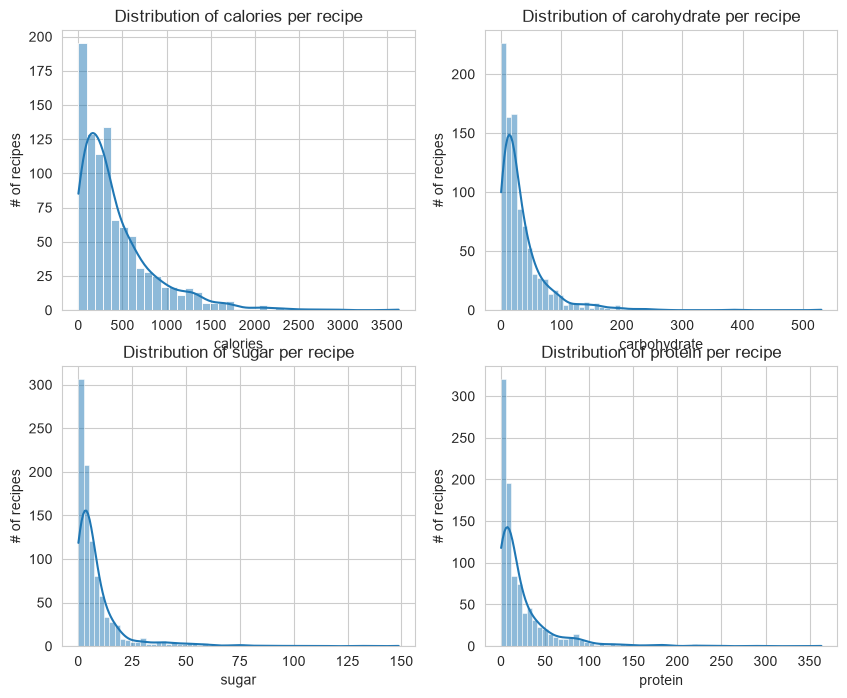

In [170]:
fig, axes= plt.subplots(2, 2, figsize=(10, 8))
sns.histplot(recipe, x= 'calories', kde= True, ax= axes[0, 0])
axes[0, 0].set_title("Distribution of calories per recipe")
axes[0, 0].set_xlabel('calories')
axes[0, 0].set_ylabel('# of recipes')

sns.histplot(recipe, x= 'carbohydrate', kde= True, ax= axes[0, 1])
axes[0, 1].set_title("Distribution of carohydrate per recipe")
axes[0, 1].set_xlabel('carbohydrate')
axes[0, 1].set_ylabel('# of recipes')

sns.histplot(recipe, x= 'sugar', kde= True, ax= axes[1, 0])
axes[1, 0].set_title("Distribution of sugar per recipe")
axes[1, 0].set_xlabel('sugar')
axes[1, 0].set_ylabel('# of recipes')

sns.histplot(recipe, x= 'protein', kde= True, ax= axes[1, 1])
axes[1, 1].set_title("Distribution of protein per recipe")
axes[1, 1].set_xlabel('protein')
axes[1, 1].set_ylabel('# of recipes')

plt.show()

many recipes apper to be right skewed for sugar, protein, carbohydrate, and calories, meaning most recipes in our dataset
record high amounts of sugar, protein, carbohydrate, and calories

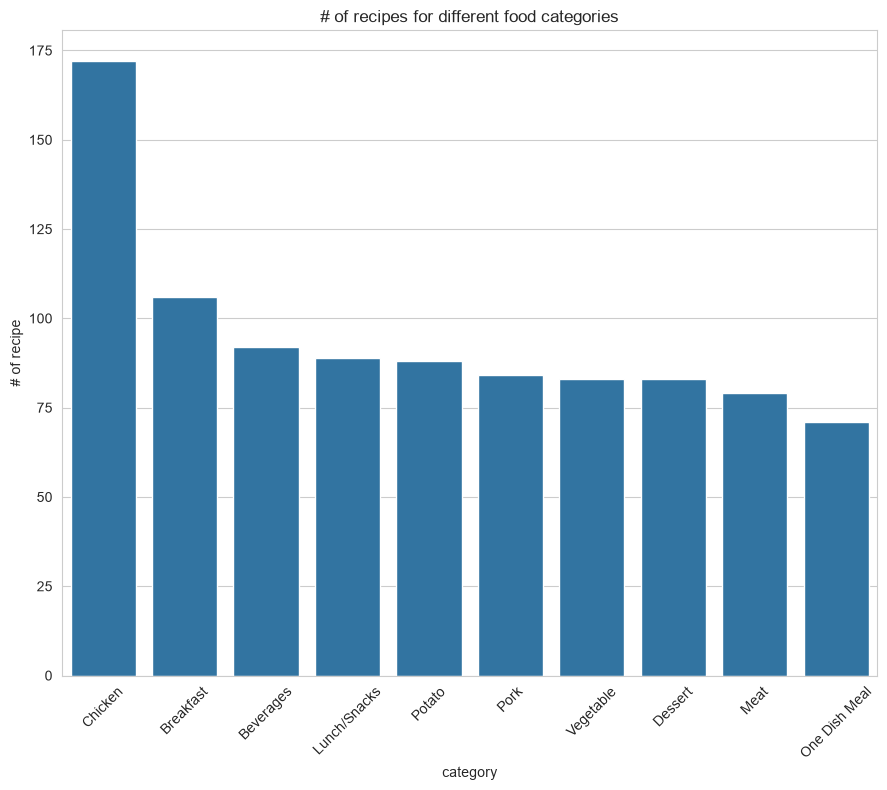

In [171]:
plt.figure(figsize= (9, 8))
sns.countplot(recipe, x='category', order= recipe['category'].value_counts().index)
plt.title('# of recipes for different food categories')
plt.xlabel('category')
plt.ylabel('# of recipe')
plt.xticks(rotation= 45)
plt.tight_layout()
plt.show()

chicken has the highest number of recipe count

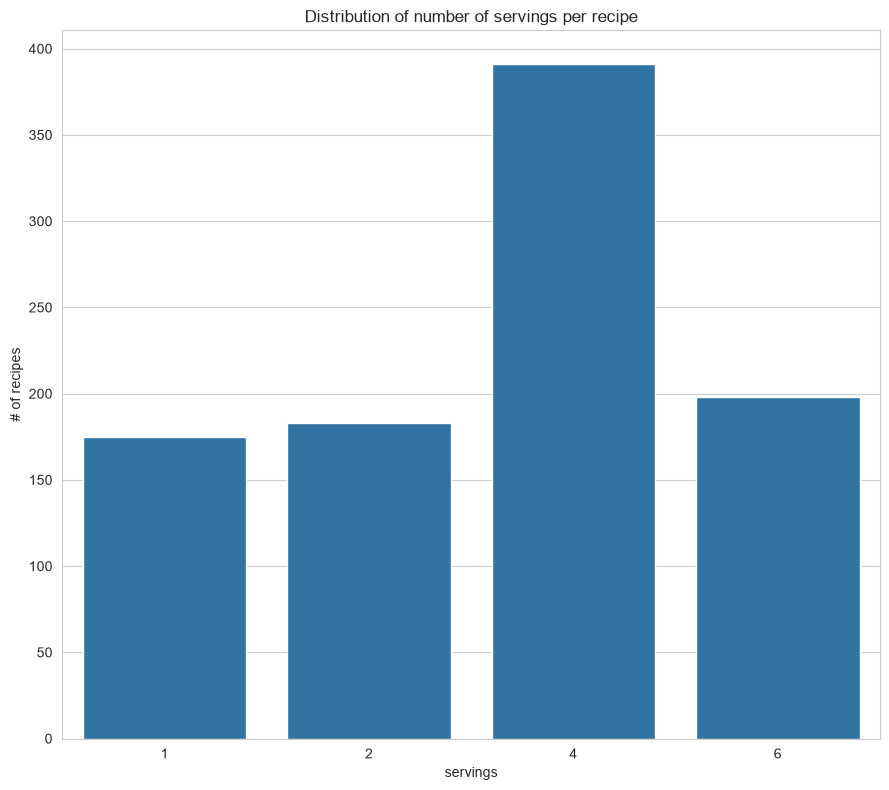

In [172]:
plt.figure(figsize=(9, 8))

sns.countplot(recipe, x='servings')
plt.title('Distribution of number of servings per recipe')
plt.ylabel('# of recipes')
plt.xlabel('servings')
plt.tight_layout()
plt.show()

most recipes are 4 servings

multivariate analysis

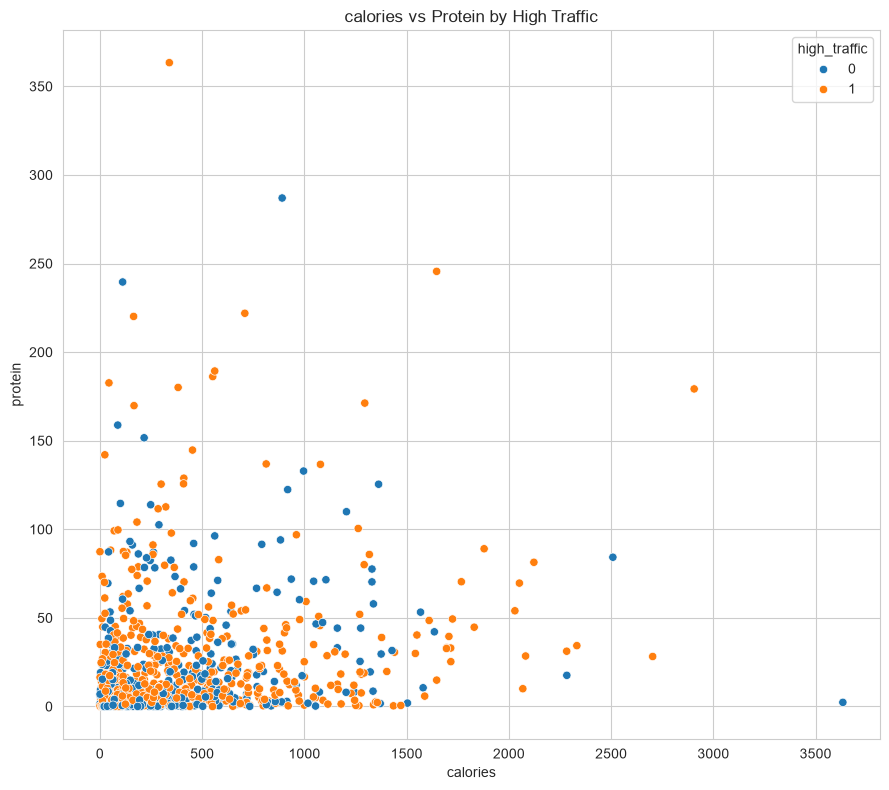

In [173]:
plt.figure(figsize=(9, 8))
sns.scatterplot(recipe, x='calories', y='protein', hue= 'high_traffic')
plt.title('calories vs Protein by High Traffic')
plt.xlabel('calories')
plt.ylabel('protein')
plt.tight_layout()
plt.show()

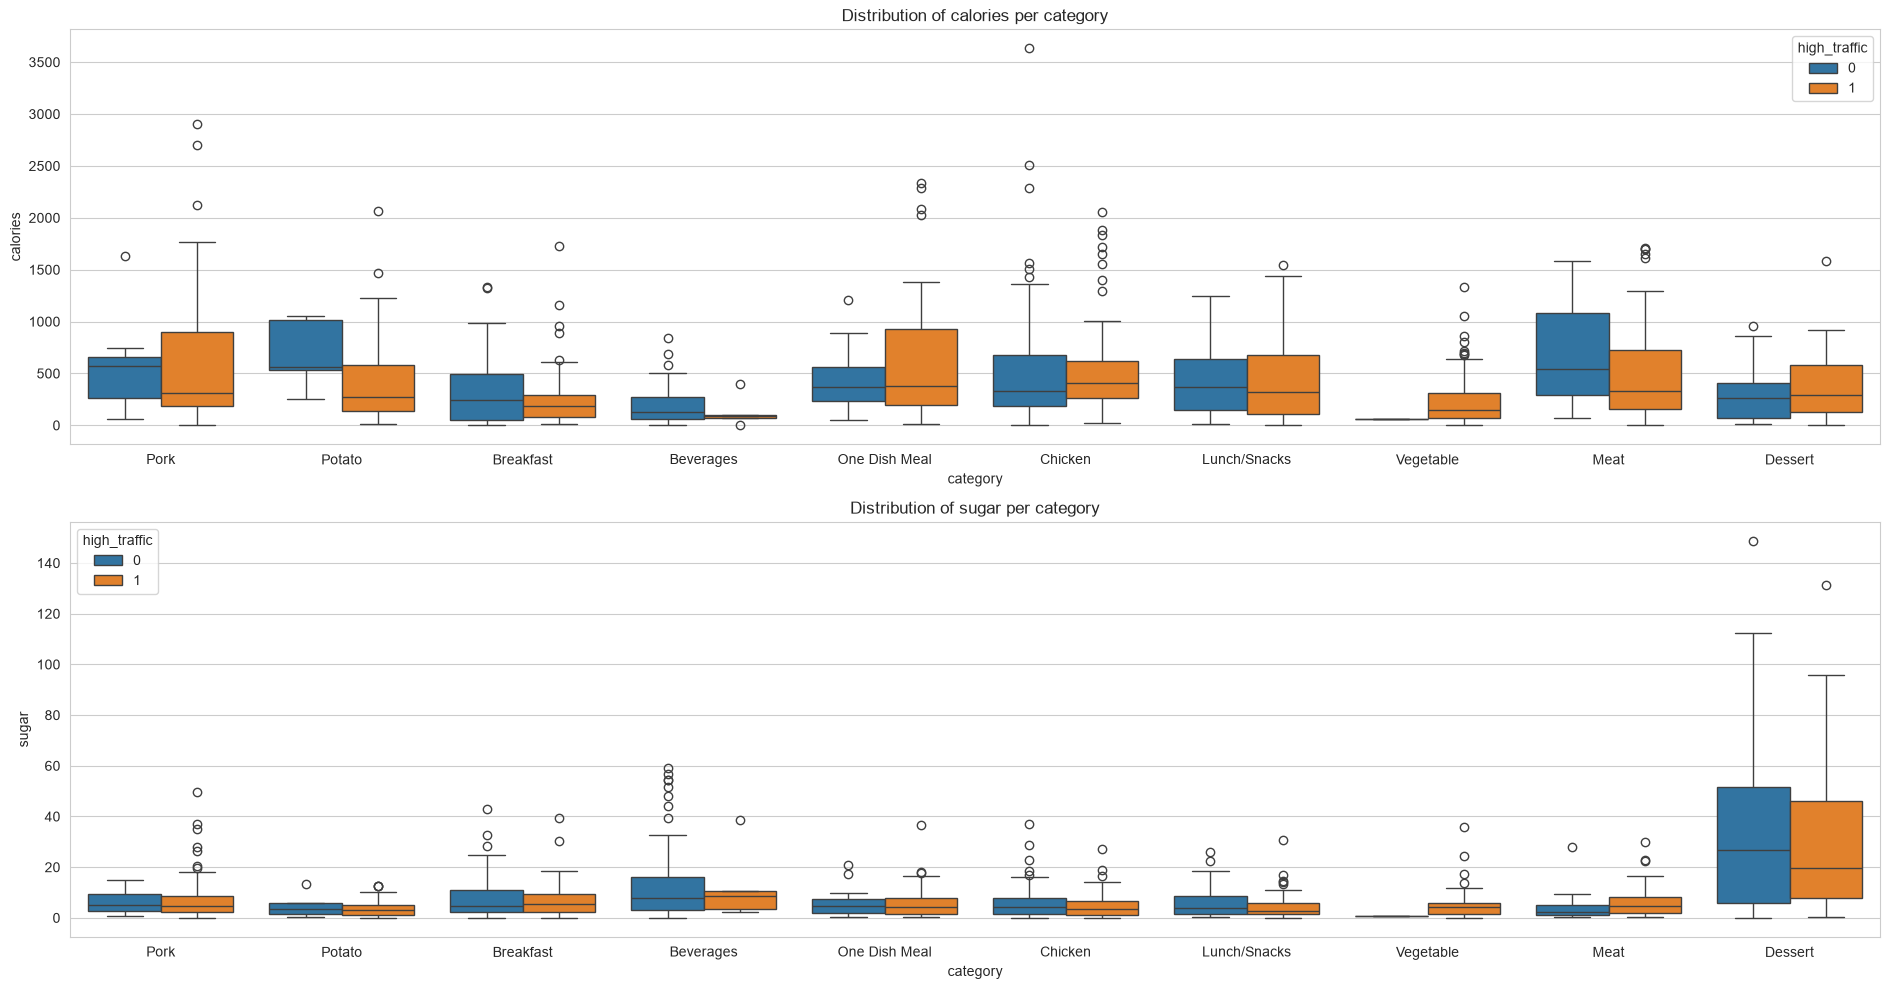

In [174]:
fig, ax= plt.subplots(2, 1, figsize=(19, 10))

sns.boxplot(recipe, x='category', y='calories', hue= 'high_traffic', ax= ax[0])
sns.boxplot(recipe, x='category', y='sugar', hue= 'high_traffic', ax= ax[1])
ax[0].set_title('Distribution of calories per category')
ax[0].set_xlabel('category')
ax[0].set_ylabel('calories')
ax[1].set_title('Distribution of sugar per category')
ax[1].set_xlabel('category')
ax[1].set_ylabel('sugar')
plt.tight_layout()
plt.show()


high traffic recipies cluster in prok, One Dish meal, Lunch/snacks and Desert

## Model Development and Evaluation

In [175]:
pip install category_encoders

Note: you may need to restart the kernel to use updated packages.


In [176]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import(
    precision_score,
    recall_score,
    roc_auc_score,
    classification_report,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    cross_val_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from category_encoders import OneHotEncoder
from sklearn.compose import ColumnTransformer



Feature columns will be: calories, carbohydrate, sugar, protein, category, servings and target column will be high_traffic

In [177]:
feat_cols= ['calories', 'carbohydrate','sugar','protein', 'category','servings' ]
target_column= 'high_traffic'

X= recipe[feat_cols]
y= recipe[target_column]

In [178]:
X.shape

(947, 6)

In [179]:
y.shape

(947,)

simple baseline: Logistic Regression

In [180]:
X_train, X_test, y_train, y_test= train_test_split(X, y, random_state=42, stratify=y)

In [181]:
print(y_train.mean())
print(y_test.mean())
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)


0.6056338028169014
0.6075949367088608
(710, 6)
(710,)
(237, 6)
(237,)


In [182]:
numeric_features = [
    'calories', 'carbohydrate', 'sugar',
    'protein', 'servings'
]

categorical_features = ['category']

In [183]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='value'), categorical_features)
    ]
)

In [184]:
lr_pipe= make_pipeline(
    preprocessor,
    LogisticRegression(class_weight='balanced',max_iter= 1000, random_state=42)
)

In [185]:
lr_pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['calories','carbohydrate','sugar','protein','category','servings']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthro

In [186]:
y_pred_lr= lr_pipe.predict(X_test)

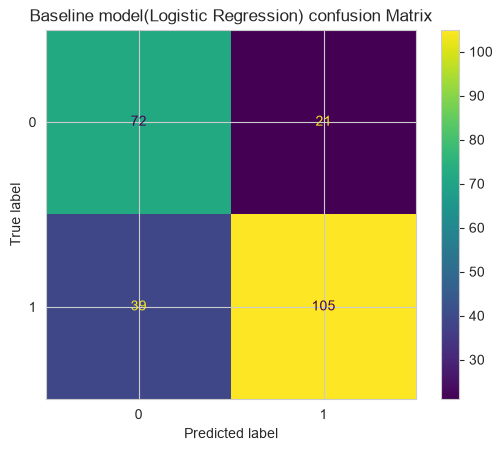

In [187]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr, values_format="d")
plt.title("Baseline model(Logistic Regression) confusion Matrix")
plt.show()

In [188]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.65      0.77      0.71        93
           1       0.83      0.73      0.78       144

    accuracy                           0.75       237
   macro avg       0.74      0.75      0.74       237
weighted avg       0.76      0.75      0.75       237



Logistic regression model has a 75% accuracy

In [189]:
def model_eval(y_true: pd.Series, y_pred: pd.Series, y_pred_proba: pd.Series) -> dict[str, int]:
    """"Evaluates model performance
    ===========================
    params
        y_pred: predicted value
        y_true: training values
        y_pred_proba: predicted probabilities

    ===========================
    return
        dict
            precision, recall, auc_roc_score, f1_score
    
    """

    precision= precision_score(y_true, y_pred, zero_division=0)
    recall= recall_score(y_true, y_pred, zero_division=0)
    f1= f1_score(y_true, y_pred, zero_division=0)
    auc_roc= roc_auc_score(y_true, y_pred_proba)

    return{
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'auc_roc': auc_roc
    }

In [190]:
y_pred_proba_lr= lr_pipe.predict_proba(X_test)[:,1]

In [191]:
lr_metrics= model_eval(y_pred_lr, y_test, y_pred_proba_lr)

In [192]:
lr_metrics

{'precision': 0.7291666666666666,
 'recall': 0.8333333333333334,
 'f1': 0.7777777777777778,
 'auc_roc': 1.0}

Logistic regression model has a 73% precission rate, 83% accuracy rate, and can perfectly seperate the High traffic from the not High traffic

In [193]:
dt_pipe= make_pipeline(
    preprocessor,
    DecisionTreeClassifier(random_state=42)
)

In [194]:
dt_pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('decisiontreeclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['calories','carbohydrate','sugar','protein','category','servings']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pass

In [195]:
y_pred_dt= dt_pipe.predict(X_test)

In [196]:
y_pred_proba_dt= dt_pipe.predict_proba(X_test)[:,1]

In [197]:
dt_metrics= model_eval(y_pred_dt, y_test, y_pred_proba_dt)

In [198]:
dt_metrics

{'precision': 0.6736111111111112,
 'recall': 0.7348484848484849,
 'f1': 0.7028985507246377,
 'auc_roc': 1.0}

In [199]:
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.55      0.62      0.59        93
           1       0.73      0.67      0.70       144

    accuracy                           0.65       237
   macro avg       0.64      0.65      0.64       237
weighted avg       0.66      0.65      0.66       237



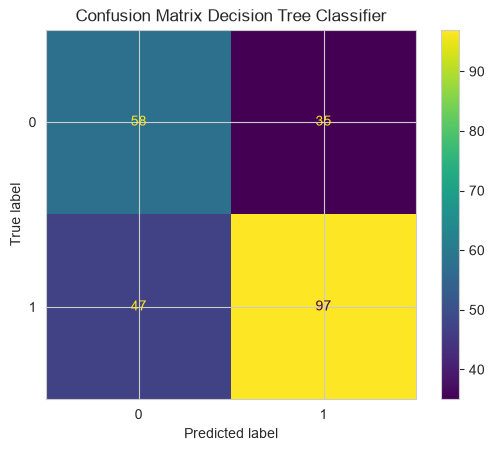

In [200]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_dt, values_format='d')
plt.title("Confusion Matrix Decision Tree Classifier")
plt.show()

In [201]:
rf_pipe= make_pipeline(
    preprocessor,
    RandomForestClassifier(random_state=42, n_jobs= -1, class_weight= 'balanced')
)

In [202]:
rf_pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('randomforestclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['calories','carbohydrate','sugar','protein','category','servings']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pass

In [203]:
y_pred_rf= rf_pipe.predict(X_test)

In [204]:
y_pred_proba_rf= rf_pipe.predict_proba(X_test)[:,1]

In [205]:
rf_metrics= model_eval(y_pred_rf, y_test, y_pred_proba_rf)

In [206]:
rf_metrics

{'precision': 0.6805555555555556,
 'recall': 0.8166666666666667,
 'f1': 0.7424242424242424,
 'auc_roc': 1.0}

In [211]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.61      0.76      0.68        93
           1       0.82      0.68      0.74       144

    accuracy                           0.71       237
   macro avg       0.71      0.72      0.71       237
weighted avg       0.73      0.71      0.72       237



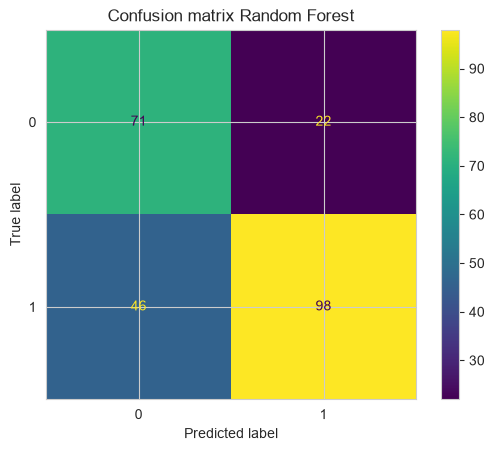

In [212]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, values_format='d')
plt.title('Confusion matrix Random Forest')
plt.show()

In [213]:
comparison= pd.DataFrame([
    {'model': 'logistic regression', **lr_metrics},
    {'model': 'decision tree', **dt_metrics},
    {'model': 'random forest', **rf_metrics},  
]).set_index('model')

In [214]:
comparison

,precision,recall,f1,auc_roc
model,,,,
logistic regression,0.729167,0.833333,0.777778,1.0
decision tree,0.673611,0.734848,0.702899,1.0
random forest,0.680556,0.816667,0.742424,1.0


Logistic Regression outperforms Decision Tree and Random forest with an accuracy of 75%